# DS422 (ML-I) Lab — Rain Prediction (Will It Rain Tomorrow?)

**Name:** Imam Hossain Safin
**ID:** 232-35-512
**Course:** DS422 — Machine Learning I (Lab)

**Objective:** Predict whether it will rain tomorrow from today's weather measurements (temperature, rainfall, humidity, pressure, wind and cloud cover).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv("/content/drive/MyDrive/ML I Report/weather_based_rain_prediction_dataset.csv")
df.head()

,MinTemp,MaxTemp,Rainfall,Humidity,Pressure,WindSpeed,WindGustSpeed,Cloud,RainTomorrow
0,11.24,29.13,3.27,80.12,988.70,22.44,4.84,8,1
1,28.52,44.54,27.01,47.96,1026.72,16.75,47.79,5,0
2,21.96,36.83,43.54,70.81,984.58,38.72,14.43,3,0
3,17.96,40.38,44.90,91.38,987.61,2.32,64.29,3,0
4,4.68,28.19,37.39,81.44,1023.30,10.52,7.18,4,0


In [4]:
df.columns

Index(['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity', 'Pressure', 'WindSpeed',
       'WindGustSpeed', 'Cloud', 'RainTomorrow'],
      dtype='object')

In [5]:
print(df.shape)

(55996, 9)


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 55996 entries, 0 to 55995
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   MinTemp        55996 non-null  float64
 1   MaxTemp        55996 non-null  float64
 2   Rainfall       55996 non-null  float64
 3   Humidity       55996 non-null  float64
 4   Pressure       55996 non-null  float64
 5   WindSpeed      55996 non-null  float64
 6   WindGustSpeed  55996 non-null  float64
 7   Cloud          55996 non-null  int64  
 8   RainTomorrow   55996 non-null  int64  
dtypes: float64(7), int64(2)
memory usage: 3.8 MB


In [7]:
df.describe()

,MinTemp,MaxTemp,Rainfall,Humidity,Pressure,WindSpeed,WindGustSpeed,Cloud,RainTomorrow
count,55996.000000,55996.000000,55996.000000,55996.000000,55996.000000,55996.000000,55996.000000,55996.000000,55996.000000
mean,14.980261,29.999969,25.072246,60.036898,1007.611395,29.923130,39.924658,3.991071,0.186031
std,8.650340,8.651273,14.443142,23.120471,15.871427,17.296153,23.125211,2.580666,0.389135
min,0.000000,15.000000,0.000000,20.000000,980.000000,0.000000,0.000000,0.000000,0.000000
25%,7.500000,22.470000,12.540000,39.977500,993.920000,14.860000,19.937500,2.000000,0.000000
50%,14.990000,30.060000,25.060000,60.090000,1007.620000,29.860000,39.945000,4.000000,0.000000
75%,22.460000,37.520000,37.552500,79.980000,1021.350000,44.900000,59.940000,6.000000,0.000000
max,30.000000,45.000000,50.000000,100.000000,1035.000000,60.000000,80.000000,8.000000,1.000000


In [8]:
# Missing values per column
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

MinTemp          0
MaxTemp          0
Rainfall         0
Humidity         0
Pressure         0
WindSpeed        0
WindGustSpeed    0
Cloud            0
RainTomorrow     0
dtype: int64

Total missing values: 0


RainTomorrow
0    45579
1    10417
Name: count, dtype: int64
RainTomorrow
0    0.814
1    0.186
Name: proportion, dtype: float64


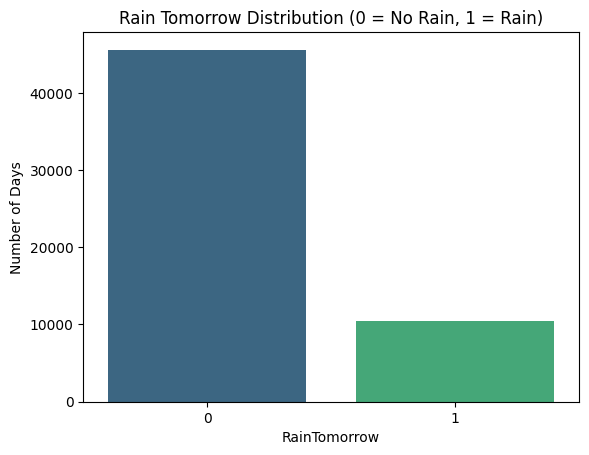

In [9]:
# Target distribution: how often does it rain tomorrow?
print(df["RainTomorrow"].value_counts())
print(df["RainTomorrow"].value_counts(normalize=True).round(3))

sns.countplot(data=df, x="RainTomorrow", hue="RainTomorrow", palette="viridis", legend=False)
plt.title("Rain Tomorrow Distribution (0 = No Rain, 1 = Rain)")
plt.xlabel("RainTomorrow")
plt.ylabel("Number of Days")
plt.show()

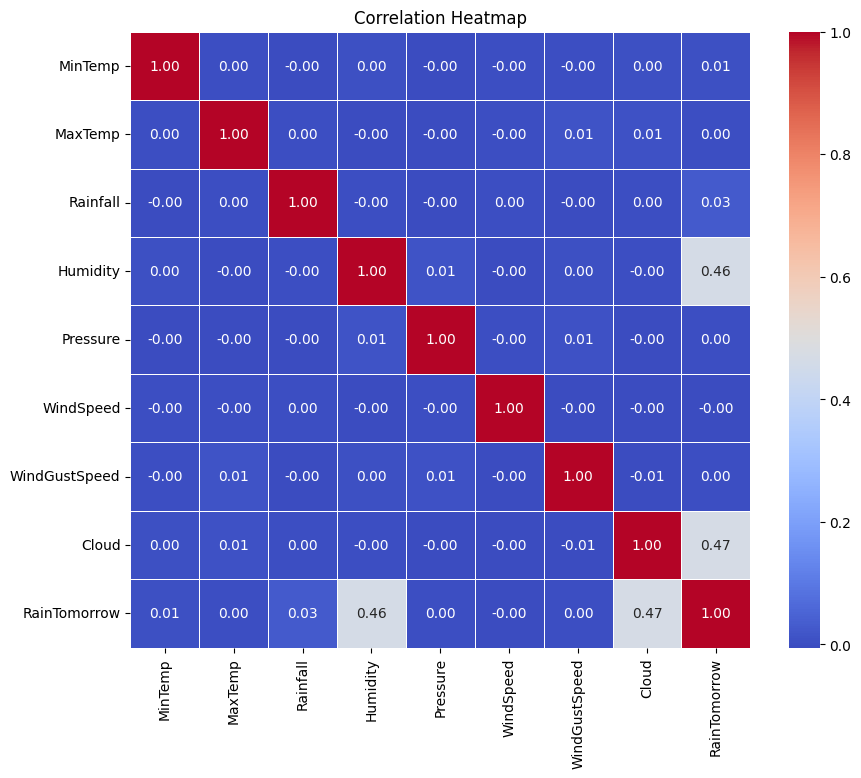

Correlation with RainTomorrow (strongest first):
Cloud            0.466
Humidity         0.463
Rainfall         0.029
MinTemp          0.006
WindSpeed       -0.003
WindGustSpeed    0.001
MaxTemp          0.000
Pressure         0.000
Name: RainTomorrow, dtype: float64


In [10]:
# Correlation between features (and with the target)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

print("Correlation with RainTomorrow (strongest first):")
print(df.corr(numeric_only=True)["RainTomorrow"].drop("RainTomorrow").sort_values(key=abs, ascending=False).round(3))

### Rain rate by cloud cover
Cloud and Humidity are the only features correlated with the target. The rain rate per cloud value shows a sharp step at 5 oktas.

In [ ]:
# Rain rate for each cloud-cover value (0-8 oktas)
rain_by_cloud = df.groupby("Cloud")["RainTomorrow"].mean().round(3)
print("Share of days followed by rain, by cloud cover:")
print(rain_by_cloud)
print("\nCloud 0-4 rain rate:", round(df[df["Cloud"] <= 4]["RainTomorrow"].mean(), 3))
print("Cloud 5-8 rain rate:", round(df[df["Cloud"] >= 5]["RainTomorrow"].mean(), 3))


Share of days followed by rain, by cloud cover:
Cloud
0    0.000
1    0.000
2    0.000
3    0.000
4    0.000
5    0.421
6    0.421
7    0.425
8    0.420
Name: RainTomorrow, dtype: float64

Cloud 0-4 rain rate: 0.0
Cloud 5-8 rain rate: 0.422


In [11]:
# Run all cleaning checks
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nIQR outlier counts per feature:")
for col in df.columns.drop("RainTomorrow"):
    q1, q3 = df[col].quantile(0.25), df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"  {col}: {outliers}")

print("\nLogically inconsistent rows (kept, as explained above):")
print("  MinTemp > MaxTemp        :", (df["MinTemp"] > df["MaxTemp"]).sum())
print("  WindGustSpeed < WindSpeed:", (df["WindGustSpeed"] < df["WindSpeed"]).sum())

Total missing values: 0
Duplicate rows: 0

IQR outlier counts per feature:
  MinTemp: 0
  MaxTemp: 0
  Rainfall: 0
  Humidity: 0
  Pressure: 0
  WindSpeed: 0
  WindGustSpeed: 0
  Cloud: 0

Logically inconsistent rows (kept, as explained above):
  MinTemp > MaxTemp        : 6918
  WindGustSpeed < WindSpeed: 21129


In [12]:
# No rows need to be removed; drop_duplicates() is run as a safeguard
df = df.drop_duplicates()
print("Shape after cleaning:", df.shape)

Shape after cleaning: (55996, 9)


In [13]:
# Separate features (X) and target (y)
X = df.drop(columns=["RainTomorrow"])
y = df["RainTomorrow"]

print("Feature matrix shape:", X.shape)
print("Features:", X.columns.tolist())
print("Target balance (rain rate):", round(y.mean(), 3))

Feature matrix shape: (55996, 8)
Features: ['MinTemp', 'MaxTemp', 'Rainfall', 'Humidity', 'Pressure', 'WindSpeed', 'WindGustSpeed', 'Cloud']
Target balance (rain rate): 0.186


In [14]:
from sklearn.model_selection import train_test_split

# 80% train / 20% test, stratified so both sets keep the same rain ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("Rain rate in train:", round(y_train.mean(), 3))
print("Rain rate in test :", round(y_test.mean(), 3))

X_train shape: (44796, 8)
X_test shape : (11200, 8)
Rain rate in train: 0.186
Rain rate in test : 0.186


In [15]:
from sklearn.preprocessing import StandardScaler

feature_names = X.columns.tolist()

scaler = StandardScaler()
X_train[feature_names] = scaler.fit_transform(X_train[feature_names])  # fit on training data only
X_test[feature_names] = scaler.transform(X_test[feature_names])          # same scaling for test data

print("Scaling done. Sample of scaled training data:")
print(X_train.head(2))

Scaling done. Sample of scaled training data:
        MinTemp   MaxTemp  Rainfall  Humidity  Pressure  WindSpeed  \
49069 -0.243698  0.656911 -0.458075  0.774669 -0.075109  -1.320912   
38453 -0.269127  0.510196  0.537669  1.110183  0.503954  -0.976075   

       WindGustSpeed     Cloud  
49069      -1.558663  1.167414  
38453       1.646247  1.167414  


In [16]:
# Models: Logistic Regression, KNN, Decision Tree, Random Forest, SVC
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score

results = {}      # scores and predictions of every model, used in Section 6
models = {}       # the trained models themselves
summary_rows = [] # one row per model for the comparison table

def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    y_pred_train = model.predict(X_tr)

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_te)[:, 1]
    else:
        y_score = model.decision_function(X_te)

    acc_train = accuracy_score(y_tr, y_pred_train)
    acc_test = accuracy_score(y_te, y_pred)
    auc = roc_auc_score(y_te, y_score)

    results[name] = {"y_pred": y_pred, "y_score": y_score, "ROC-AUC": auc}
    models[name] = model
    summary_rows.append({"Model": name, "Train Accuracy": acc_train,
                         "Test Accuracy": acc_test, "ROC-AUC": auc})

    print(f"===== {name} =====")
    print("Train Accuracy:", round(acc_train, 4))
    print("Test Accuracy :", round(acc_test, 4))
    print("ROC-AUC Score :", round(auc, 4))
    print("\nClassification Report (Test):\n", classification_report(y_te, y_pred))
    print("Confusion Matrix (Test):\n", confusion_matrix(y_te, y_pred))
    return model

In [17]:
# Model 1: Logistic Regression (baseline)
lr_model = evaluate_model("Logistic Regression",
                          LogisticRegression(max_iter=1000),
                          X_train, y_train, X_test, y_test)

===== Logistic Regression =====
Train Accuracy: 0.934
Test Accuracy : 0.9311
ROC-AUC Score : 0.9766

Classification Report (Test):
               precision    recall  f1-score   support

           0       0.95      0.96      0.96      9116
           1       0.83      0.80      0.81      2084

    accuracy                           0.93     11200
   macro avg       0.89      0.88      0.88     11200
weighted avg       0.93      0.93      0.93     11200

Confusion Matrix (Test):
 [[8770  346]
 [ 426 1658]]


In [18]:
# Model 2: K-Nearest Neighbors
knn_model = evaluate_model("KNN",
                           KNeighborsClassifier(n_neighbors=5),
                           X_train, y_train, X_test, y_test)

===== KNN =====
Train Accuracy: 0.9765
Test Accuracy : 0.9587
ROC-AUC Score : 0.9879

Classification Report (Test):
               precision    recall  f1-score   support

           0       0.97      0.98      0.97      9116
           1       0.90      0.88      0.89      2084

    accuracy                           0.96     11200
   macro avg       0.94      0.93      0.93     11200
weighted avg       0.96      0.96      0.96     11200

Confusion Matrix (Test):
 [[8912  204]
 [ 259 1825]]


In [19]:
# Model 3: Decision Tree
dt_model = evaluate_model("Decision Tree",
                          DecisionTreeClassifier(random_state=42),
                          X_train, y_train, X_test, y_test)

===== Decision Tree =====
Train Accuracy: 1.0
Test Accuracy : 1.0
ROC-AUC Score : 1.0

Classification Report (Test):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      9116
           1       1.00      1.00      1.00      2084

    accuracy                           1.00     11200
   macro avg       1.00      1.00      1.00     11200
weighted avg       1.00      1.00      1.00     11200

Confusion Matrix (Test):
 [[9116    0]
 [   0 2084]]


In [20]:
# Model 4: Random Forest
rf_model = evaluate_model("Random Forest",
                          RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
                          X_train, y_train, X_test, y_test)

===== Random Forest =====
Train Accuracy: 1.0
Test Accuracy : 1.0
ROC-AUC Score : 1.0

Classification Report (Test):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00      9116
           1       1.00      1.00      1.00      2084

    accuracy                           1.00     11200
   macro avg       1.00      1.00      1.00     11200
weighted avg       1.00      1.00      1.00     11200

Confusion Matrix (Test):
 [[9116    0]
 [   0 2084]]


In [21]:
# Model 5: Support Vector Classifier
# SVC is very slow on 44,796 training rows, so it is trained on a stratified
# sample of 10,000 training rows (same rain ratio) and tested on the full test set.
X_svc, _, y_svc, _ = train_test_split(X_train, y_train, train_size=10000,
                                      stratify=y_train, random_state=42)

svc_model = evaluate_model("SVC",
                           SVC(kernel="rbf", random_state=42),
                           X_svc, y_svc, X_test, y_test)

===== SVC =====
Train Accuracy: 0.9809
Test Accuracy : 0.9766
ROC-AUC Score : 0.9965

Classification Report (Test):
               precision    recall  f1-score   support

           0       0.98      0.99      0.99      9116
           1       0.95      0.93      0.94      2084

    accuracy                           0.98     11200
   macro avg       0.96      0.96      0.96     11200
weighted avg       0.98      0.98      0.98     11200

Confusion Matrix (Test):
 [[9007  109]
 [ 153 1931]]


In [22]:
# Summary of all models
summary_df = pd.DataFrame(summary_rows).sort_values("Test Accuracy", ascending=False)
summary_df

,Model,Train Accuracy,Test Accuracy,ROC-AUC
2,Decision Tree,1.000000,1.000000,1.000000
3,Random Forest,1.000000,1.000000,1.000000
4,SVC,0.980900,0.976607,0.996541
1,KNN,0.976493,0.958661,0.987876
0,Logistic Regression,0.933990,0.931071,0.976646


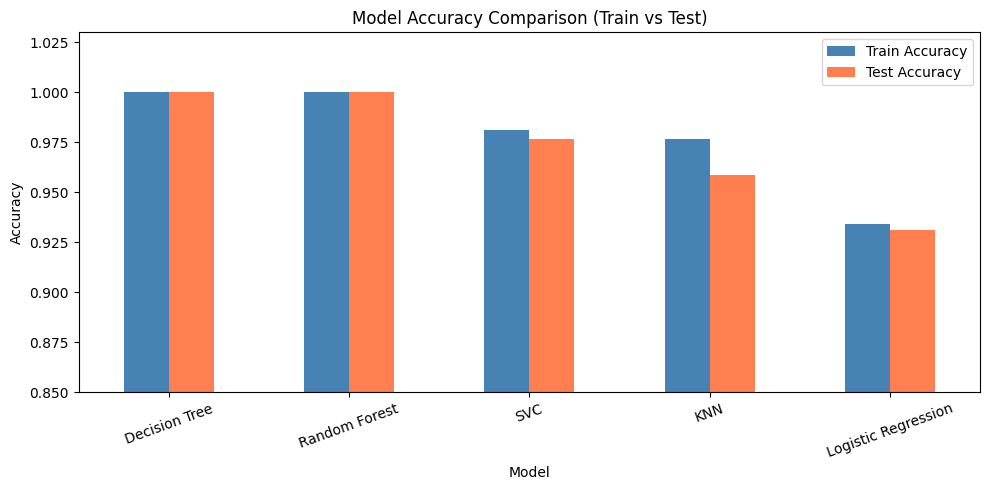

In [23]:
# Accuracy comparison: train vs test for every model
summary_df.set_index("Model")[["Train Accuracy", "Test Accuracy"]].plot(
    kind="bar", figsize=(10, 5), color=["steelblue", "coral"])
plt.title("Model Accuracy Comparison (Train vs Test)")
plt.ylabel("Accuracy")
plt.ylim(0.85, 1.03)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

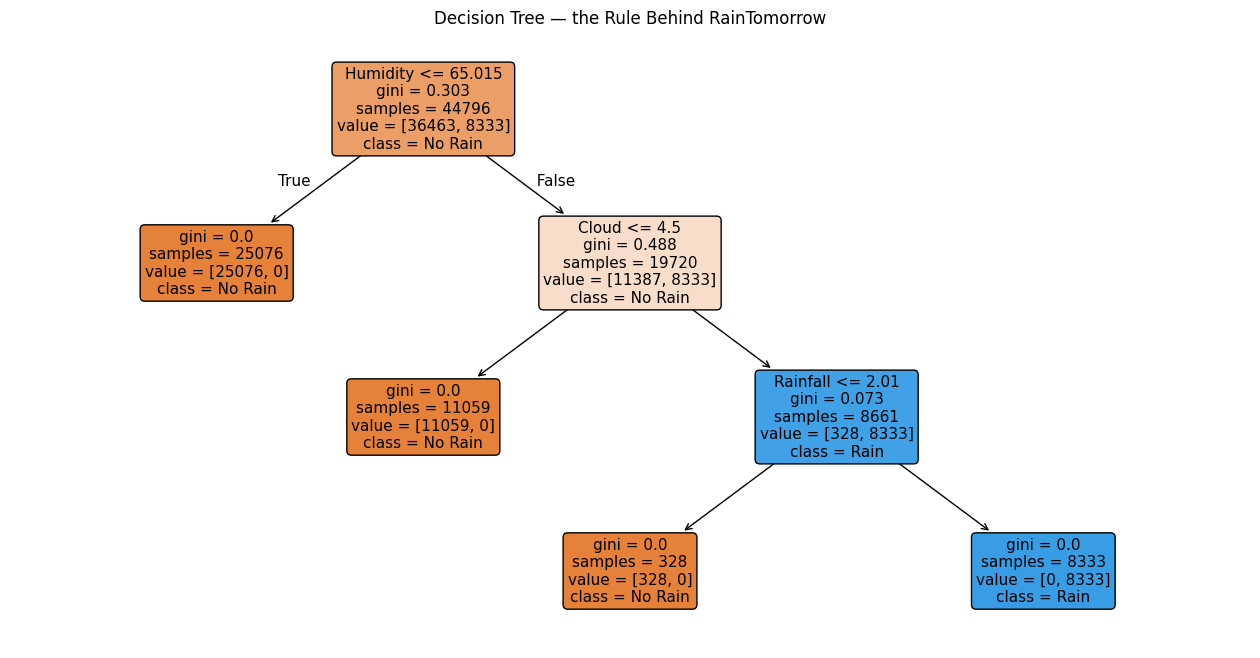

Same tree on unscaled data — test accuracy: 1.0


In [24]:
# The trained Decision Tree — notice how small it is.
# It has rediscovered the exact rule hidden in the data (read it top to bottom).
# Trees are not affected by scaling, so for a readable diagram the identical tree is
# re-trained here on the original unscaled values — thresholds in real units (°C, %, mm).
from sklearn.tree import plot_tree

X_train_raw = scaler.inverse_transform(X_train)
X_test_raw = scaler.inverse_transform(X_test)
display_tree = DecisionTreeClassifier(random_state=42).fit(X_train_raw, y_train)

plt.figure(figsize=(16, 8))
plot_tree(display_tree, feature_names=feature_names,
          class_names=["No Rain", "Rain"], filled=True, rounded=True, fontsize=11)
plt.title("Decision Tree — the Rule Behind RainTomorrow")
plt.show()

print("Same tree on unscaled data — test accuracy:", accuracy_score(y_test, display_tree.predict(X_test_raw)))

### Verify the discovered rule
The tree only asks three questions. Below, its rules are printed as text and the same rule is checked on all 55,996 rows.

In [ ]:
# Read the tree's rules as text, then verify the rule on EVERY row of the dataset
print(export_text(display_tree, feature_names=feature_names))
print("Tree depth:", display_tree.get_depth(), "| leaves:", display_tree.get_n_leaves())

rule = ((df["Humidity"] > 65) & (df["Cloud"] > 4.5) & (df["Rainfall"] > 2)).astype(int)
matches = (rule == df["RainTomorrow"]).sum()
print(f"\nRule: Humidity > 65 AND Cloud > 4.5 AND Rainfall > 2")
print(f"Matches {matches} of {len(df)} rows = {matches / len(df):.2%}")


|--- Humidity <= 65.01
|   |--- class: 0
|--- Humidity >  65.01
|   |--- Cloud <= 4.50
|   |   |--- class: 0
|   |--- Cloud >  4.50
|   |   |--- Rainfall <= 2.01
|   |   |   |--- class: 0
|   |   |--- Rainfall >  2.01
|   |   |   |--- class: 1

Tree depth: 3 | leaves: 4

Rule: Humidity > 65 AND Cloud > 4.5 AND Rainfall > 2
Matches 55996 of 55996 rows = 100.00%


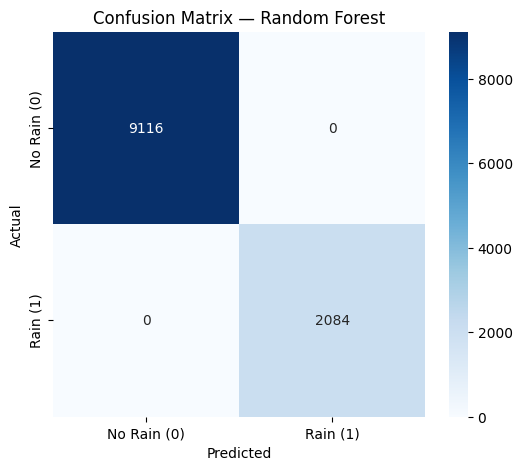

In [25]:
# Confusion Matrix of the best model (Random Forest) as a heatmap
cm = confusion_matrix(y_test, results["Random Forest"]["y_pred"])

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["No Rain (0)", "Rain (1)"],
            yticklabels=["No Rain (0)", "Rain (1)"])
plt.title("Confusion Matrix — Random Forest")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

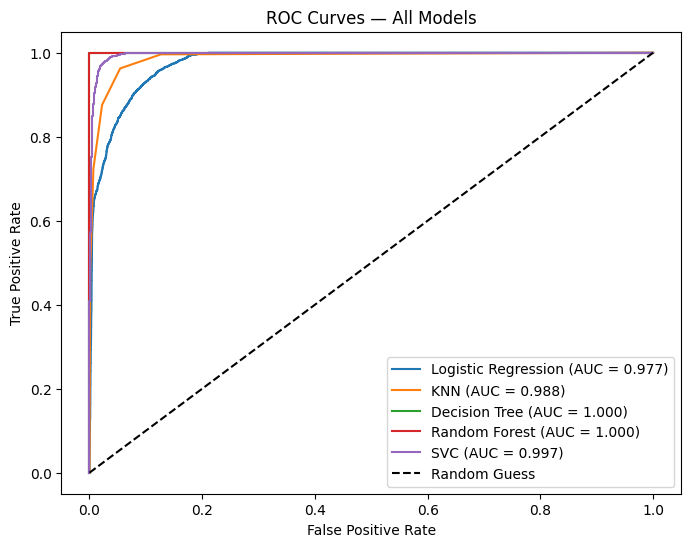

In [26]:
# ROC curves of all models on the same plot
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["y_score"])
    plt.plot(fpr, tpr, label=f"{name} (AUC = {res['ROC-AUC']:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random Guess")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves — All Models")
plt.legend(loc="lower right")
plt.show()

Feature importances:
Humidity         0.4862
Cloud            0.4742
Rainfall         0.0273
WindSpeed        0.0026
Pressure         0.0025
MinTemp          0.0025
WindGustSpeed    0.0024
MaxTemp          0.0024
dtype: float64


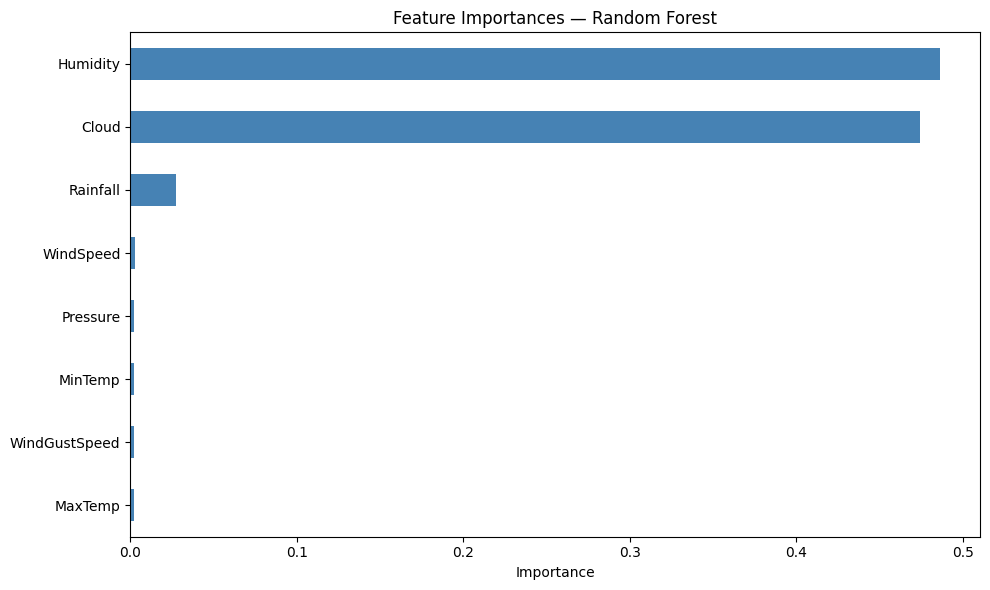

In [27]:
# Which features matter most? (Random Forest feature importance)
importances = pd.Series(models["Random Forest"].feature_importances_,
                        index=X.columns).sort_values(ascending=False)

print("Feature importances:")
print(importances.round(4))

importances.sort_values().plot(kind="barh", figsize=(10, 6), color="steelblue")
plt.title("Feature Importances — Random Forest")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [28]:
import joblib

# Save the best model
joblib.dump(models["Random Forest"], "random_forest_rain_model.pkl")
print("Model saved as random_forest_rain_model.pkl")

# Load it back and test it on the first test day
loaded_model = joblib.load("random_forest_rain_model.pkl")
print("Loaded model:", type(loaded_model).__name__)
print("Prediction for first test day:", loaded_model.predict(X_test[:1])[0],
      "| Actual value:", y_test.iloc[0])

Model saved as random_forest_rain_model.pkl
Loaded model: RandomForestClassifier
Prediction for first test day: 0 | Actual value: 0
